In [2]:
from src.data_loader import DataLoader
from src.data_analyzer import DataAnalyzer

loader = DataLoader("../data/raw/bank-full.csv")
df = loader.load_data()

analyzer = DataAnalyzer(df)

print(f"Dataset shape: {df.shape}")

Dataset shape: (45211, 17)


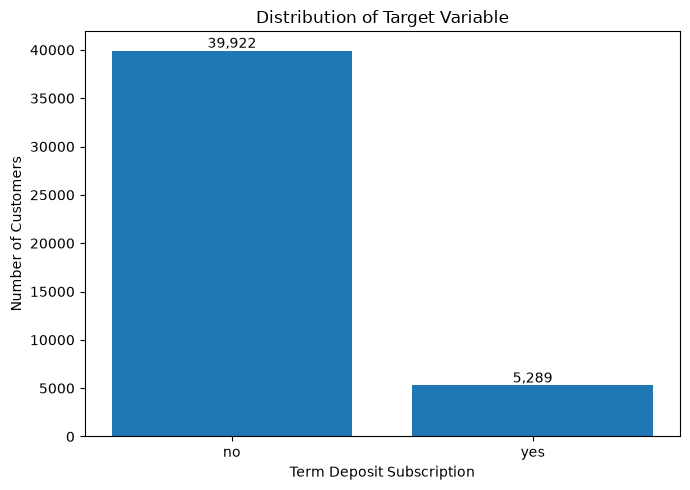

In [3]:
import matplotlib.pyplot as plt

target_counts = df["y"].value_counts().reindex(["no", "yes"])

plt.figure(figsize=(7, 5))
plt.bar(target_counts.index, target_counts.values)

plt.title("Distribution of Target Variable")
plt.xlabel("Term Deposit Subscription")
plt.ylabel("Number of Customers")

for index, value in enumerate(target_counts.values):
    plt.text(index, value + 300, f"{value:,}", ha="center")

plt.tight_layout()
plt.show()

In [4]:
import pandas as pd
import matplotlib.pyplot as pyplot

job_substription = pd.crosstab(
    df["job"],
    df["y"],
    normalize="index"
) * 100

job_substription = job_substription.sort_values(
    by="yes",
    ascending=True
)

print(job_substription.round(2))

y                 no    yes
job                        
blue-collar    92.73   7.27
entrepreneur   91.73   8.27
housemaid      91.21   8.79
services       91.12   8.88
technician     88.94  11.06
unknown        88.19  11.81
self-employed  88.16  11.84
admin.         87.80  12.20
management     86.24  13.76
unemployed     84.50  15.50
retired        77.21  22.79
student        71.32  28.68


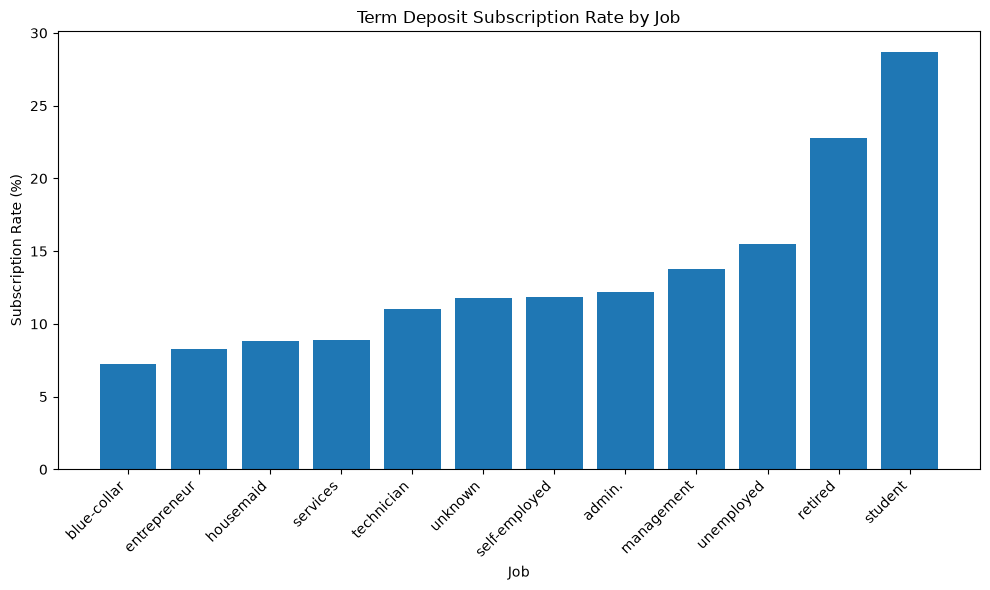

In [5]:
plt.figure(figsize=(10, 6))

plt.bar(
    job_substription.index, job_substription["yes"]
)

plt.title("Term Deposit Subscription Rate by Job")
plt.xlabel("Job")
plt.ylabel("Subscription Rate (%)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

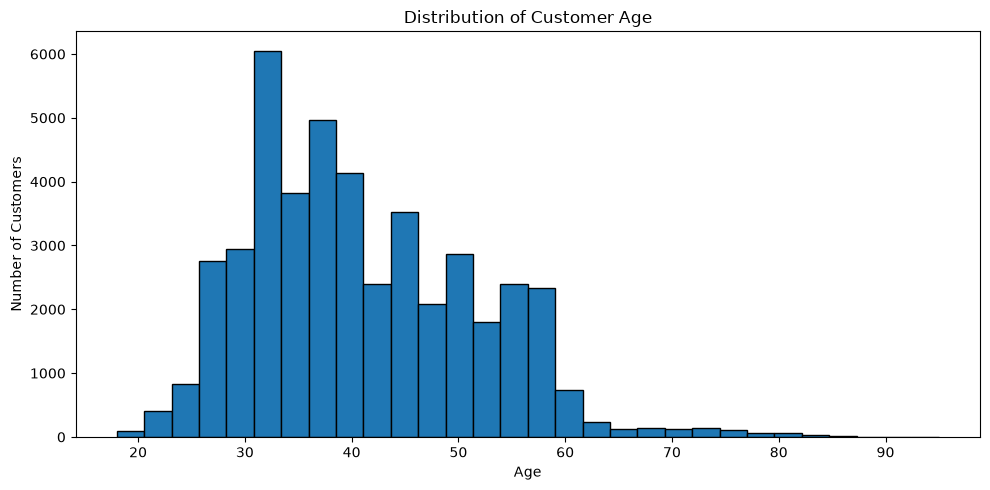

In [6]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["age"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Customer Age")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [7]:
df.age.describe()

count    45211.000000
mean        40.936210
std         10.618762
min         18.000000
25%         33.000000
50%         39.000000
75%         48.000000
max         95.000000
Name: age, dtype: float64

In [8]:
age_bins = [18, 30, 40, 50, 60, 100]

age_labels = [
    "18-29",
    "30-39",
    "40-49",
    "50-59",
    "60+"
]

df["age_group"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

df["age_group"].value_counts().sort_index()

age_group
18-29     5273
30-39    18089
40-49    11655
50-59     8410
60+       1784
Name: count, dtype: int64

In [9]:
age_subscription = pd.crosstab(
    df["age_group"],
    df["y"],
    normalize="index"
) * 100

print(age_subscription.round(2))

y             no    yes
age_group              
18-29      82.40  17.60
30-39      89.42  10.58
40-49      90.88   9.12
50-59      90.67   9.33
60+        66.37  33.63


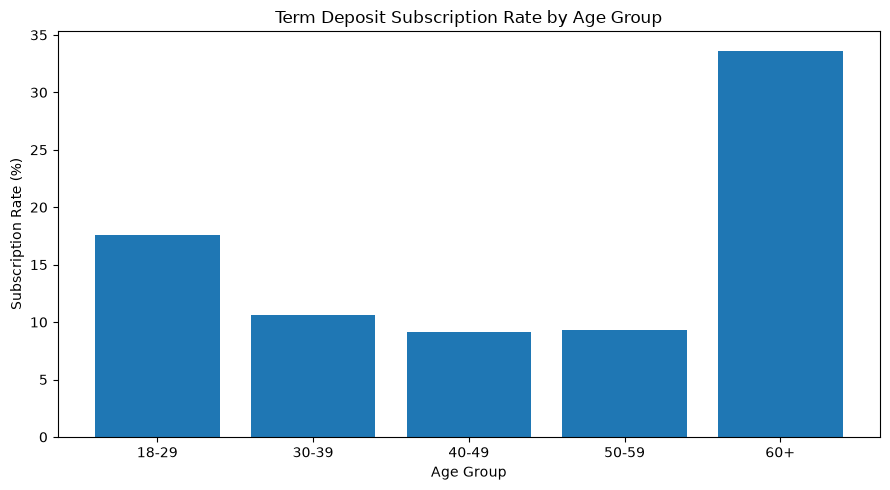

In [10]:
plt.figure(figsize=(9, 5))

plt.bar(
    age_subscription.index.astype(str),
    age_subscription["yes"]
)

plt.title("Term Deposit Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")

plt.tight_layout()
plt.show()

In [11]:
df["duration"].describe()

count    45211.000000
mean       258.163080
std        257.527812
min          0.000000
25%        103.000000
50%        180.000000
75%        319.000000
max       4918.000000
Name: duration, dtype: float64

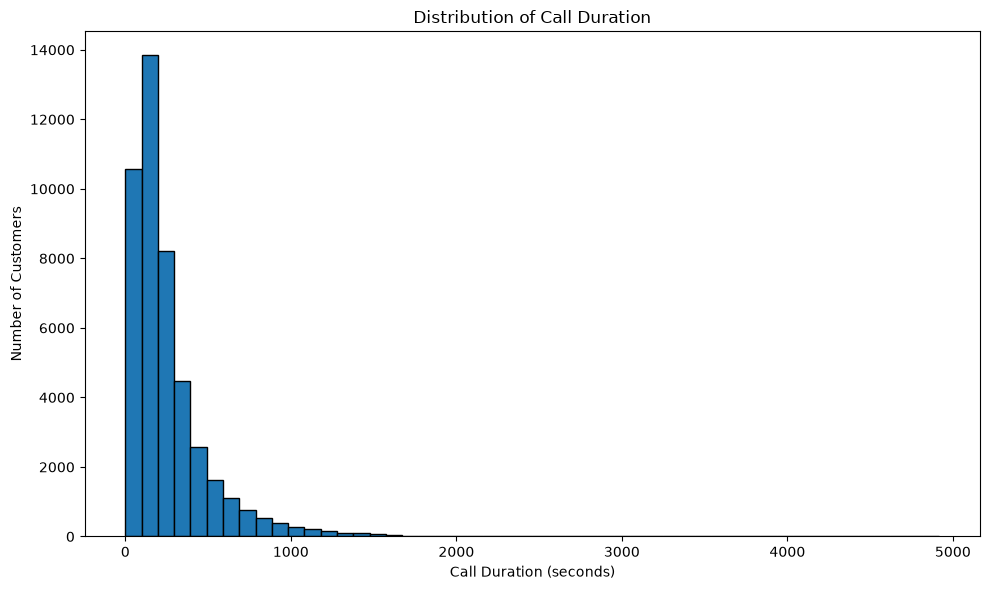

In [12]:
plt.figure(figsize=(10, 6))

plt.hist(
    df["duration"],
    bins=50,
    edgecolor = "black"
)

plt.title("Distribution of Call Duration")
plt.xlabel("Call Duration (seconds)")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

In [13]:
df.groupby("y")["duration"].describe()

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,221.182806,207.383237,0.0,95.0,164.0,279.0,4918.0
yes,5289.0,537.294574,392.525262,8.0,244.0,426.0,725.0,3881.0


In [14]:
poutcome_subscription = pd.crosstab(
    df["poutcome"],
    df["y"],
    normalize="index"
) * 100

poutcome_subscription = poutcome_subscription.sort_values(
    by="yes",
    ascending=False
)

print(poutcome_subscription.round(2))

y            no    yes
poutcome              
success   35.27  64.73
other     83.32  16.68
failure   87.39  12.61
unknown   90.84   9.16


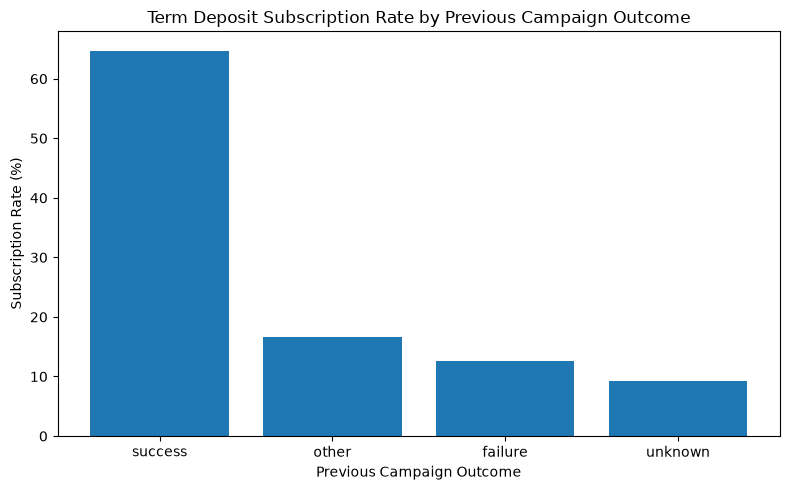

In [15]:
plt.figure(figsize=(8, 5))

plt.bar(
    poutcome_subscription.index,
    poutcome_subscription["yes"]
)

plt.title("Term Deposit Subscription Rate by Previous Campaign Outcome")
plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")

plt.tight_layout()
plt.show()

In [16]:
poutcome_counts = df["poutcome"].value_counts()

poutcome_summary = pd.DataFrame({
    "count": poutcome_counts,
    "percentage": (
        poutcome_counts / len(df) * 100
    ).round(2),
    "subscription_rate": (
        df.groupby("poutcome", observed=False)["y"]
        .apply(lambda values: (values == "yes").mean() * 100)
        .round(2)
    ),
})

print(poutcome_summary)

          count  percentage  subscription_rate
poutcome                                      
failure    4901       10.84              12.61
other      1840        4.07              16.68
success    1511        3.34              64.73
unknown   36959       81.75               9.16


y            no    yes
marital               
single    85.05  14.95
divorced  88.05  11.95
married   89.88  10.12


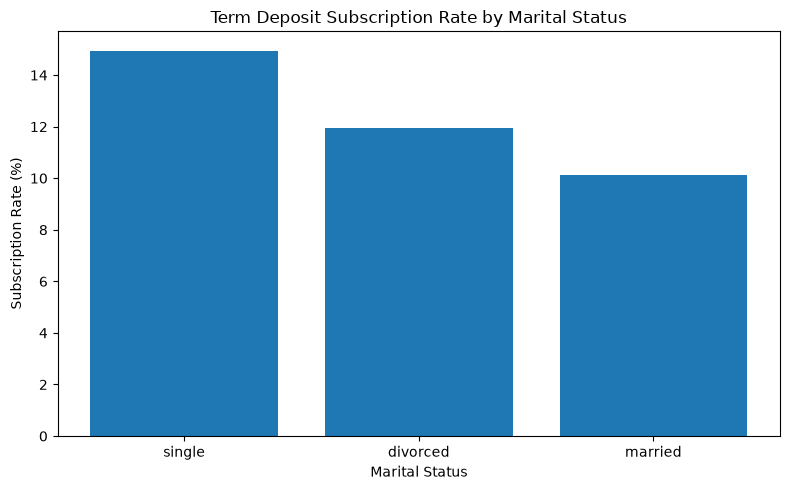

In [17]:
df["marital"].value_counts()

marital_subscription = pd.crosstab(
    df["marital"],
    df["y"],
    normalize="index"
) * 100

marital_subscription = marital_subscription.sort_values(
    by="yes",
    ascending=False
)

print(marital_subscription.round(2))

plt.figure(figsize=(8, 5))

plt.bar(
    marital_subscription.index,
    marital_subscription["yes"]
)

plt.title("Term Deposit Subscription Rate by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Subscription Rate (%)")

plt.tight_layout()
plt.show()

y             no    yes
education              
tertiary   84.99  15.01
unknown    86.43  13.57
secondary  89.44  10.56
primary    91.37   8.63


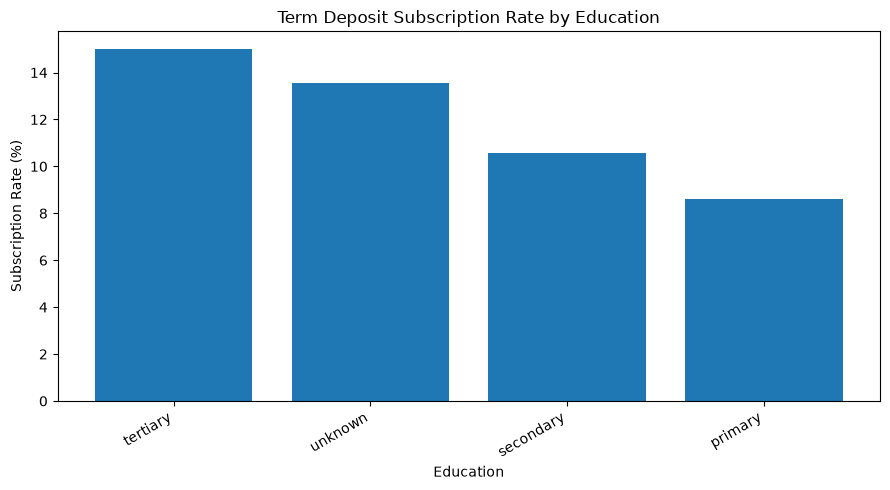

In [18]:
df["education"].value_counts()

education_subscription = pd.crosstab(
    df["education"],
    df["y"],
    normalize="index"
) * 100

education_subscription = education_subscription.sort_values(
    by="yes",
    ascending=False
)

print(education_subscription.round(2))

plt.figure(figsize=(9, 5))

plt.bar(
    education_subscription.index,
    education_subscription["yes"]
)

plt.title("Term Deposit Subscription Rate by Education")
plt.xlabel("Education")
plt.ylabel("Subscription Rate (%)")

plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [19]:
df["housing"].value_counts()

housing_subscription = pd.crosstab(
    df["housing"],
    df["y"],
    normalize="index"
) * 100

print(housing_subscription.round(2))

y          no   yes
housing            
no       83.3  16.7
yes      92.3   7.7


In [20]:
df["loan"].value_counts()

loan_subscription = pd.crosstab(
    df["loan"],
    df["y"],
    normalize="index"
) * 100

print(loan_subscription.round(2))

y        no    yes
loan              
no    87.34  12.66
yes   93.32   6.68


In [21]:
df["default"].value_counts()

default_subscription = pd.crosstab(
    df["default"],
    df["y"],
    normalize="index"
) * 100

print(default_subscription.round(2))

y           no    yes
default              
no       88.20  11.80
yes      93.62   6.38


In [22]:
df["default"].value_counts()

default
no     44396
yes      815
Name: count, dtype: int64

In [23]:
df["balance"].describe()

count     45211.000000
mean       1362.272058
std        3044.765829
min       -8019.000000
25%          72.000000
50%         448.000000
75%        1428.000000
max      102127.000000
Name: balance, dtype: float64

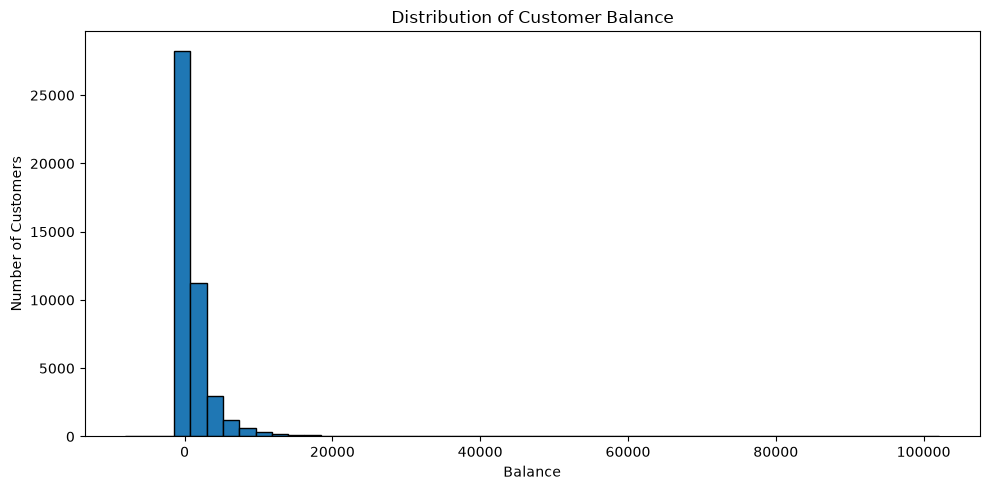

In [24]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["balance"],
    bins=50,
    edgecolor="black"
)

plt.title("Distribution of Customer Balance")
plt.xlabel("Balance")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

/var/folders/4c/xtjvxh0s3b37z1nyjq9128f00000gn/T/ipykernel_4452/2004769128.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(


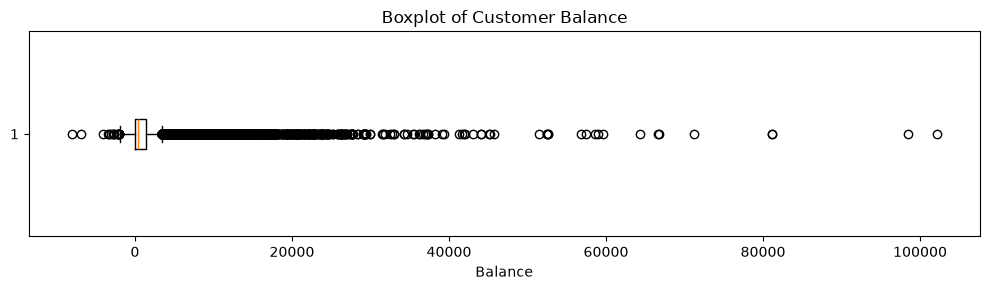

In [25]:
plt.figure(figsize=(10, 3))

plt.boxplot(
    df["balance"],
    vert=False
)

plt.title("Boxplot of Customer Balance")
plt.xlabel("Balance")

plt.tight_layout()
plt.show()

In [26]:
balance_by_target = df.groupby("y")["balance"].describe()

display(balance_by_target)

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,1303.714969,2974.195473,-8019.0,58.0,417.0,1345.0,102127.0
yes,5289.0,1804.267915,3501.104777,-3058.0,210.0,733.0,2159.0,81204.0


In [27]:
df["campaign"].describe()

count    45211.000000
mean         2.763841
std          3.098021
min          1.000000
25%          1.000000
50%          2.000000
75%          3.000000
max         63.000000
Name: campaign, dtype: float64

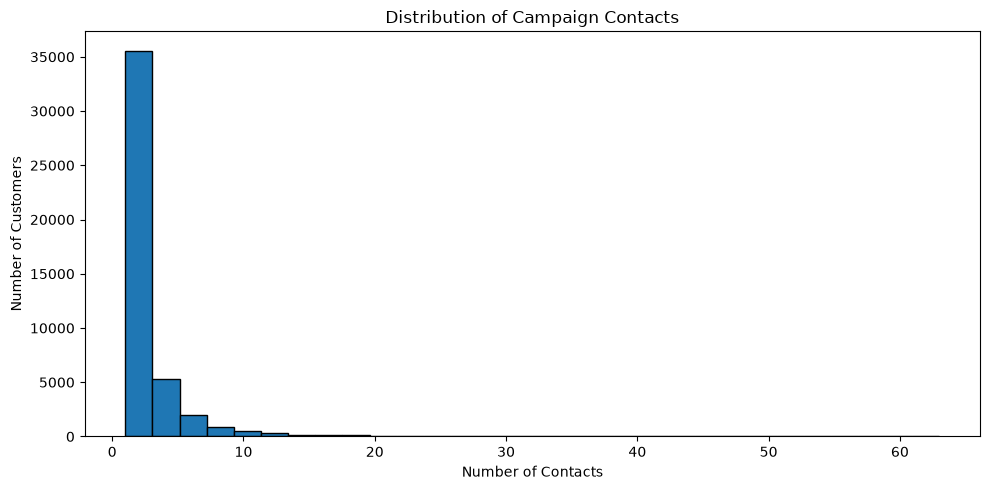

In [28]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df["campaign"], bins=30, edgecolor="black")
plt.title("Distribution of Campaign Contacts")
plt.xlabel("Number of Contacts")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

/var/folders/4c/xtjvxh0s3b37z1nyjq9128f00000gn/T/ipykernel_4452/2454296720.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df["campaign"], vert=False)


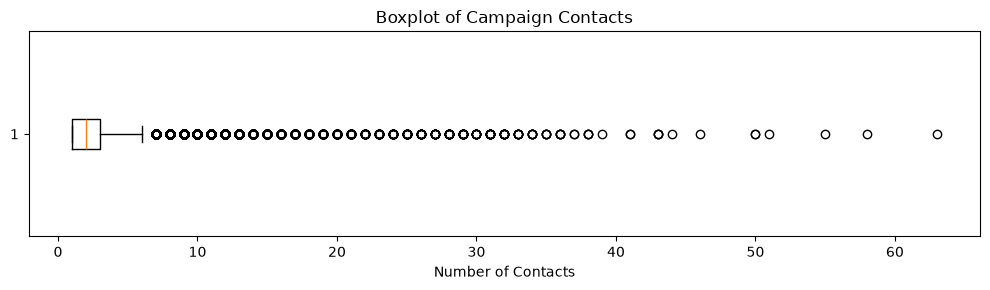

In [29]:
plt.figure(figsize=(10, 3))
plt.boxplot(df["campaign"], vert=False)
plt.title("Boxplot of Campaign Contacts")
plt.xlabel("Number of Contacts")
plt.tight_layout()
plt.show()

In [30]:
campaign_by_target = (
    df.groupby("y")["campaign"]
    .describe()
)

display(campaign_by_target)

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,2.846350,3.212767,1.0,1.0,2.0,3.0,63.0
yes,5289.0,2.141047,1.921826,1.0,1.0,2.0,3.0,32.0


In [31]:
df["previous"].describe()

count    45211.000000
mean         0.580323
std          2.303441
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        275.000000
Name: previous, dtype: float64

In [32]:
previous_counts = df["previous"].value_counts()

print("Số khách hàng previous = 0:", previous_counts.get(0, 0))
print(
    "Tỷ lệ previous = 0:",
    f"{(df['previous'].eq(0).mean() * 100):.2f}%"
)

print("\nCác giá trị previous xuất hiện nhiều nhất:")
display(previous_counts.head(10))

Số khách hàng previous = 0: 36954
Tỷ lệ previous = 0: 81.74%

Các giá trị previous xuất hiện nhiều nhất:


previous
0    36954
1     2772
2     2106
3     1142
4      714
5      459
6      277
7      205
8      129
9       92
Name: count, dtype: int64

In [33]:
previous_by_target = (
    df.groupby("y")["previous"]
    .describe()
)

display(previous_by_target)

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,39922.0,0.502154,2.256771,0.0,0.0,0.0,0.0,275.0
yes,5289.0,1.170354,2.553272,0.0,0.0,0.0,1.0,58.0


In [34]:
previous_group = pd.Series(
    "No previous contact",
    index=df.index
)

previous_group[df["previous"] > 0] = "Previous contact"

previous_conversion = pd.crosstab(
    previous_group,
    df["y"],
    normalize="index"
) * 100

display(previous_conversion.round(2))

y,no,yes
row_0,,
No previous contact,90.84,9.16
Previous contact,76.93,23.07


In [35]:
df["pdays"].describe()

count    45211.000000
mean        40.197828
std        100.128746
min         -1.000000
25%         -1.000000
50%         -1.000000
75%         -1.000000
max        871.000000
Name: pdays, dtype: float64

In [36]:
pdays_counts = df["pdays"].value_counts()

print("Số khách hàng pdays = -1:", pdays_counts.get(-1, 0))

print(
    "Tỷ lệ pdays = -1:",
    f"{(df['pdays'].eq(-1).mean() * 100):.2f}%"
)

print(
    "Số khách hàng đã được liên hệ trước đó:",
    (df["pdays"] != -1).sum()
)

Số khách hàng pdays = -1: 36954
Tỷ lệ pdays = -1: 81.74%
Số khách hàng đã được liên hệ trước đó: 8257


In [37]:
pdays_group = pd.Series(
    "No previous contact",
    index=df.index
)

pdays_group[df["pdays"] != -1] = "Previous contact"

pdays_conversion = pd.crosstab(
    pdays_group,
    df["y"],
    normalize="index"
) * 100

display(pdays_conversion.round(2))

y,no,yes
row_0,,
No previous contact,90.84,9.16
Previous contact,76.93,23.07


In [38]:
pdays_contacted = df.loc[df["pdays"] != -1, "pdays"]

display(pdays_contacted.describe())

count    8257.000000
mean      224.577692
std       115.344035
min         1.000000
25%       133.000000
50%       194.000000
75%       327.000000
max       871.000000
Name: pdays, dtype: float64

In [39]:
df["day"].describe()

count    45211.000000
mean        15.806419
std          8.322476
min          1.000000
25%          8.000000
50%         16.000000
75%         21.000000
max         31.000000
Name: day, dtype: float64

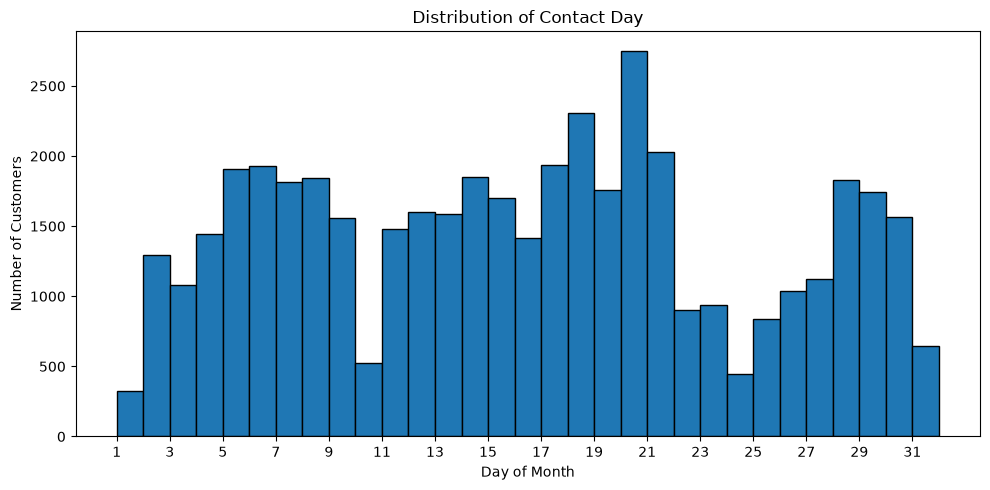

In [40]:
plt.figure(figsize=(10, 5))

plt.hist(
    df["day"],
    bins=range(1, 33),
    edgecolor="black"
)

plt.title("Distribution of Contact Day")
plt.xlabel("Day of Month")
plt.ylabel("Number of Customers")
plt.xticks(range(1, 32, 2))
plt.tight_layout()
plt.show()

In [41]:
daily_conversion = (
    df.groupby("day")["y"]
    .apply(lambda s: (s == "yes").mean() * 100)
)

display(daily_conversion.round(2))

day
1     27.95
2     14.08
3     16.50
4     15.92
5     11.26
6      9.37
7      8.64
8     10.91
9     11.47
10    23.09
11    12.24
12    15.22
13    15.21
14    11.36
15    13.98
16    13.57
17     9.08
18     9.88
19     6.94
20     6.98
21     9.92
22    17.02
23    13.42
24    13.87
25    15.83
26    11.21
27    13.38
28     7.81
29     7.39
30    17.31
31     7.15
Name: y, dtype: float64

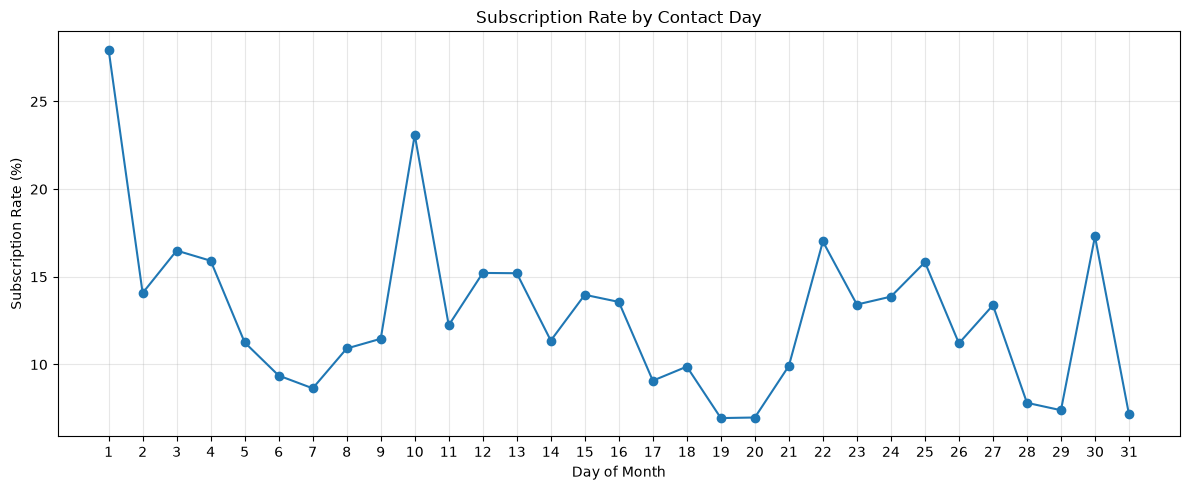

In [42]:
plt.figure(figsize=(12, 5))

plt.plot(
    daily_conversion.index,
    daily_conversion.values,
    marker="o"
)

plt.title("Subscription Rate by Contact Day")
plt.xlabel("Day of Month")
plt.ylabel("Subscription Rate (%)")
plt.xticks(range(1, 32))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
df["month"].value_counts()

month
may    13766
jul     6895
aug     6247
jun     5341
nov     3970
apr     2932
feb     2649
jan     1403
oct      738
sep      579
mar      477
dec      214
Name: count, dtype: int64

In [44]:
monthly_conversion = (
    df.groupby("month")["y"]
    .apply(lambda s: (s == "yes").mean() * 100)
)

display(monthly_conversion.round(2))

month
apr    19.68
aug    11.01
dec    46.73
feb    16.65
jan    10.12
jul     9.09
jun    10.22
mar    51.99
may     6.72
nov    10.15
oct    43.77
sep    46.46
Name: y, dtype: float64

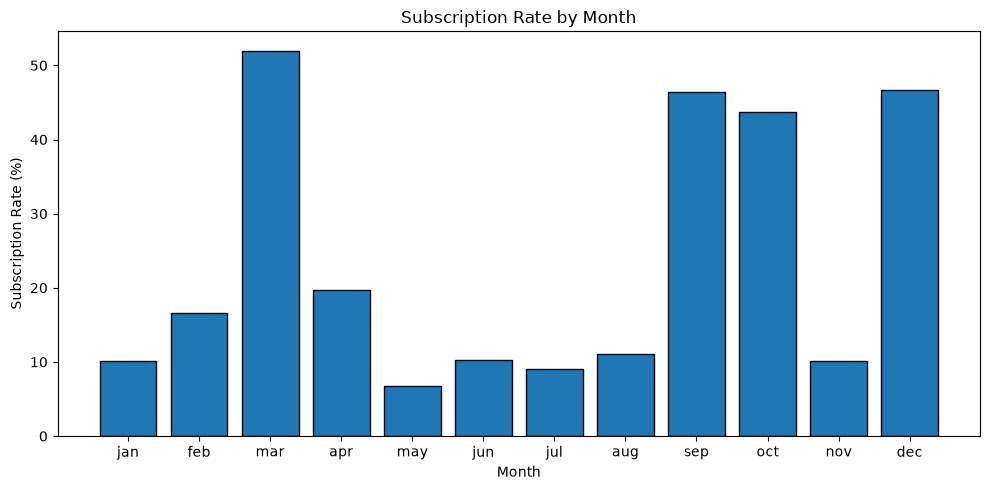

In [45]:
month_order = [
    "jan", "feb", "mar", "apr", "may", "jun",
    "jul", "aug", "sep", "oct", "nov", "dec"
]

monthly_conversion_ordered = monthly_conversion.reindex(month_order)

plt.figure(figsize=(10, 5))
plt.bar(
    monthly_conversion_ordered.index,
    monthly_conversion_ordered.values,
    edgecolor="black"
)

plt.title("Subscription Rate by Month")
plt.xlabel("Month")
plt.ylabel("Subscription Rate (%)")
plt.tight_layout()
plt.show()

In [46]:
df["contact"].value_counts()

contact
cellular     29285
unknown      13020
telephone     2906
Name: count, dtype: int64

In [47]:
contact_conversion = pd.crosstab(
    df["contact"],
    df["y"],
    normalize="index"
) * 100

display(contact_conversion.round(2))

y,no,yes
contact,,
cellular,85.08,14.92
telephone,86.58,13.42
unknown,95.93,4.07
